# CPE15 Activity 11
## GIS and GeoPandas Fundamentals

**Scenario:** Public-Service Accessibility Mapping  
**Course:** Professional Elective 1: Programming for Data Science  
**Week:** 13  
**Mode:** Individual, in class or take home  
**Suggested completion time:** 5 to 6 hours  
**Total:** 100 points

### Student Information

**Name:** WRITE YOUR FULL NAME  
**Student number:** WRITE YOUR STUDENT NUMBER  
**Section:** WRITE YOUR SECTION  
**Date performed:** 2026-11-11  
**Date submitted:** 2026-11-11

> Rename this file as `Surname_Firstname_CPE15_Activity11.ipynb` before submission.

## Activity Purpose

Represent synthetic public-service facilities as spatial and attribute data, compare point, line, and polygon roles, manage coordinate reference systems, measure in projected units, round-trip GeoJSON, and apply privacy-aware generalization.

## Learning Outcomes

1. Construct a GeoDataFrame from attributes and point geometry.
2. Explain point, line, and polygon representations.
3. Assign and transform a CRS before distance or area measurement.
4. Export, import, and reconcile GeoJSON.
5. Communicate spatial privacy, source authority, and measurement limitations.

## General Instructions

1. Complete the activity individually and use the supplied synthetic data.
2. Do not delete or rewrite a cell labeled **STARTER DATA**.
3. Write the requested prediction before executing each part.
4. Complete every **STUDENT CODE** cell and keep the output visible.
5. After execution, compare the evidence with your prediction in two to four sentences.
6. Label quantities with units, denominators, and scope.
7. Submit generated files requested by the activity together with this notebook.
8. Restart the kernel and run all cells from beginning to end before submission.

No separate laboratory report is required.

## Required CSV Files

Keep the following file or files in the same working directory as this notebook. Do not rename them.

1. `CPE15_Activity11_Accessible_Facilities.csv`

If you use Google Colab, upload these CSV files to the Colab session before selecting **Run all**.


## Part 1: Spatial and Attribute Data (10 points)

**Context:** Five fictional public-service facilities have a name, service type, daily capacity, longitude, and latitude.

### Required Tasks

1. Create a pandas DataFrame.
2. Convert coordinates to point geometry.
3. Create a GeoDataFrame in EPSG:4326.
4. Report geometry type, CRS, row count, and attribute fields.
5. Define one row precisely.

**Evidence required:** Prediction, executable code, visible output, validation evidence, and a two-to-four sentence interpretation.

### Part 1 Prediction

Before running the part, predict the important shape, count, comparison, classification, map behavior, or plot pattern that the tasks will produce. Explain the reason for your prediction.

**Prediction:** I expect 20 rows and the same six attribute fields as the CSV, plus a geometry column holding 20 Point objects. The GeoDataFrame should report EPSG:4326 because longitude and latitude are in degrees, with coordinates near 121.6 degrees east and 13.9 degrees north.

In [1]:
# STARTER DATA: Do not manually alter these values.
from pathlib import Path
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point, LineString, Polygon

DATA_FILE = Path('Copy of CPE15_Activity11_Accessible_Facilities.csv')
facilities_df = pd.read_csv(DATA_FILE)
print(f'Loaded {len(facilities_df)} facilities from {DATA_FILE.name}')

Loaded 20 facilities from Copy of CPE15_Activity11_Accessible_Facilities.csv


In [2]:
# STUDENT CODE: Build and inspect the GeoDataFrame.

# Make one Point for each longitude and latitude pair.
geometry = [Point(lon, lat) for lon, lat in zip(facilities_df['longitude'], facilities_df['latitude'])]

# Turn the pandas DataFrame into a GeoDataFrame.
facilities = gpd.GeoDataFrame(facilities_df, geometry=geometry, crs='EPSG:4326')

# Validation checks.
print('Geometry type:', facilities.geometry.geom_type.unique())
print('CRS:', facilities.crs)
print('Row count:', len(facilities))
print('Attribute fields:', list(facilities.columns))
print('Unique facility IDs:', facilities['facility_id'].nunique())
print('All geometries nonempty:', facilities.geometry.notna().all() and not facilities.geometry.is_empty.any())
print('Longitude range:', facilities['longitude'].min(), 'to', facilities['longitude'].max())
print('Latitude range:', facilities['latitude'].min(), 'to', facilities['latitude'].max())

print()
print('One row defined precisely:')
row = facilities.iloc[0]
print('facility_id:', row['facility_id'])
print('name:', row['name'])
print('service:', row['service'])
print('daily_capacity:', row['daily_capacity'], 'persons per day')
print('longitude:', row['longitude'], 'degrees east')
print('latitude:', row['latitude'], 'degrees north')
print('geometry:', row['geometry'])

Geometry type: <StringArray>
['Point']
Length: 1, dtype: str
CRS: EPSG:4326
Row count: 20
Attribute fields: ['facility_id', 'name', 'service', 'daily_capacity', 'longitude', 'latitude', 'geometry']
Unique facility IDs: 20
All geometries nonempty: True
Longitude range: 121.617 to 121.6264
Latitude range: 13.9345 to 13.94105

One row defined precisely:
facility_id: F01
name: Administrative Service Point 1
service: Administrative
daily_capacity: 45 persons per day
longitude: 121.617 degrees east
latitude: 13.9345 degrees north
geometry: POINT (121.617 13.9345)


### Part 1 Evidence and Explanation

Compare the actual result with your prediction. Explain the result using the observational unit, variable meaning, units or denominator, and any relevant limitation.

**Response:** The output matched the prediction: 20 rows, seven columns (six attributes plus geometry), Point geometry, and EPSG:4326. One row is one facility; for example, F01 is an Administrative service point with a daily capacity of 45 persons per day at 121.617 degrees east and 13.9345 degrees north. The geometry supplies location while the attributes supply identity and service meaning, so both are needed. A limitation is that the coordinates are synthetic and were not checked against a real map.

## Part 2: Points, Lines, and Polygons (10 points)

**Context:** The map needs facility locations, one illustrative walking route, and one planning extent.

### Required Tasks

1. Create a line through three ordered facility points.
2. Create a polygon enclosing the activity area.
3. Store each geometry in a GeoDataFrame with the same CRS.
4. Plot all geometry types together.
5. Explain what each geometry abstracts.

**Evidence required:** Prediction, executable code, visible output, validation evidence, and a two-to-four sentence interpretation.

### Part 2 Prediction

Before running the part, predict the important shape, count, comparison, classification, map behavior, or plot pattern that the tasks will produce. Explain the reason for your prediction.

**Prediction:** I expect one straight LineString connecting F01, F03, and F05, and one rectangular Polygon covering the activity area. All 20 facility points should fall inside the rectangle, and the point, line, and polygon layers should all share EPSG:4326.

In [3]:
# STARTER DATA: Do not manually alter these values.
route=LineString([facilities.geometry.iloc[0],facilities.geometry.iloc[2],facilities.geometry.iloc[4]])
extent=Polygon([(121.616,13.934),(121.627,13.934),(121.627,13.942),(121.616,13.942)])

Point layer: 20 facilities, Point
Line layer: 1 route, LineString
Polygon layer: 1 extent, Polygon
Same CRS: True


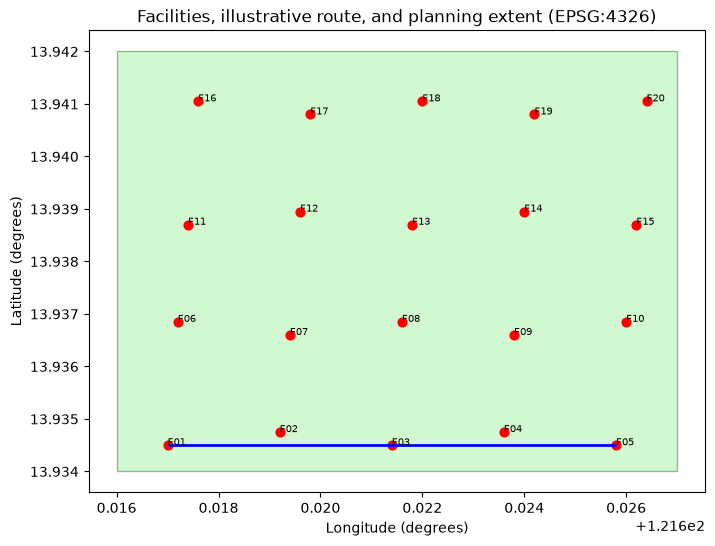

In [4]:
# STUDENT CODE: Build, plot, and interpret the three geometry roles.
%matplotlib inline

# Put the route and the extent into GeoDataFrames with the same CRS.
route_gdf = gpd.GeoDataFrame({'feature': ['Illustrative walking route']}, geometry=[route], crs='EPSG:4326')
extent_gdf = gpd.GeoDataFrame({'feature': ['Planning extent']}, geometry=[extent], crs='EPSG:4326')

print('Point layer:', len(facilities), 'facilities,', facilities.geometry.geom_type.iloc[0])
print('Line layer:', len(route_gdf), 'route,', route_gdf.geometry.geom_type.iloc[0])
print('Polygon layer:', len(extent_gdf), 'extent,', extent_gdf.geometry.geom_type.iloc[0])
print('Same CRS:', facilities.crs == route_gdf.crs == extent_gdf.crs)

fig, ax = plt.subplots(figsize=(8, 6))
extent_gdf.plot(ax=ax, facecolor='lightgreen', edgecolor='darkgreen', alpha=0.4)
route_gdf.plot(ax=ax, color='blue', linewidth=2)
facilities.plot(ax=ax, color='red', markersize=40)
for i, row in facilities.iterrows():
    ax.annotate(row['facility_id'], (row.geometry.x, row.geometry.y), fontsize=7)
ax.set_title('Facilities, illustrative route, and planning extent (EPSG:4326)')
ax.set_xlabel('Longitude (degrees)')
ax.set_ylabel('Latitude (degrees)')
plt.show()

### Part 2 Evidence and Explanation

Compare the actual result with your prediction. Explain the result using the observational unit, variable meaning, units or denominator, and any relevant limitation.

**Response:** The map showed one blue line through F01, F03, and F05 inside a green rectangle, and all 20 facility points were inside the extent. The points abstract facility locations, the line abstracts a simplified walking route, and the polygon abstracts a planning boundary. These shapes are illustrative, so the straight route is not a real road and the rectangle is not an official boundary.

## Part 3: CRS Transformation, Distance, and Area (10 points)

**Context:** Angular longitude and latitude coordinates must be projected before reporting metres or square metres.

### Required Tasks

1. Transform all layers to EPSG:32651.
2. Calculate distance from each facility to F01 in metres.
3. Calculate polygon area in hectares.
4. Verify projected CRS equality and units.
5. State projection limitations.

**Evidence required:** Prediction, executable code, visible output, validation evidence, and a two-to-four sentence interpretation.

### Part 3 Prediction

Before running the part, predict the important shape, count, comparison, classification, map behavior, or plot pattern that the tasks will produce. Explain the reason for your prediction.

**Prediction:** After transforming to EPSG:32651, coordinates and distances should be in metres. Distances to F01 should start at 0 m and rise to about 1,250 m, while the rectangle area should be about 105 hectares.

In [5]:
# STARTER DATA: Do not manually alter these values.
projected_crs='EPSG:32651'

In [6]:
# STUDENT CODE: Project before measuring and label every unit.

facilities_proj = facilities.to_crs(projected_crs)
route_proj = route_gdf.to_crs(projected_crs)
extent_proj = extent_gdf.to_crs(projected_crs)

# Distance from every facility to F01.
f01 = facilities_proj[facilities_proj['facility_id'] == 'F01'].geometry.iloc[0]
facilities_proj['distance_to_F01_m'] = facilities_proj.geometry.distance(f01)

print(facilities_proj[['facility_id', 'distance_to_F01_m']].to_string(index=False))

# Polygon area in square metres and hectares.
area_m2 = extent_proj.geometry.area.iloc[0]
print()
print('Extent area:', round(area_m2, 2), 'square metres')
print('Extent area:', round(area_m2 / 10000, 2), 'hectares')

# Validation of CRS and units.
print()
print('All layers use EPSG:32651:', facilities_proj.crs == route_proj.crs == extent_proj.crs == projected_crs)
print('Horizontal unit:', facilities_proj.crs.axis_info[0].unit_name)
print('F01 distance:', round(facilities_proj['distance_to_F01_m'].iloc[0], 2), 'metres')
print('Route length:', round(route_proj.geometry.length.iloc[0], 2), 'metres')

facility_id  distance_to_F01_m
        F01           0.000000
        F02         239.315662
        F03         475.424568
        F04         713.672224
        F05         950.848304
        F06         260.865374
        F07         348.161810
        F08         560.914144
        F09         770.595092
        F10        1006.602893
        F11         466.630864
        F12         566.800094
        F13         696.321566
        F14         902.443881
        F15        1097.283076
        F16         727.488182
        F17         759.770544
        F18         903.826646
        F19        1044.479268
        F20        1247.641191

Extent area: 1051858.36 square metres
Extent area: 105.19 hectares

All layers use EPSG:32651: True
Horizontal unit: metre
F01 distance: 0.0 metres
Route length: 950.85 metres


### Part 3 Evidence and Explanation

Compare the actual result with your prediction. Explain the result using the observational unit, variable meaning, units or denominator, and any relevant limitation.

**Response:** The projected layers all used EPSG:32651, whose horizontal unit is the metre. Distances to F01 ranged from 0 m to about 1,247.64 m, and the extent area was about 1,051,858.36 square metres or 105.19 hectares. This projection is suitable for a small area, but it still distorts distance and area far from its central meridian, so the values are local estimates.

## Part 4: GeoJSON Round Trip (10 points)

**Context:** The point layer will be exchanged as a small web-oriented vector file.

### Required Tasks

1. Export the facilities to GeoJSON in EPSG:4326.
2. Read the file back.
3. Verify row count, IDs, CRS, geometry type, and nonempty geometry.
4. Report file size.
5. Explain what round-trip validation cannot prove.

**Evidence required:** Prediction, executable code, visible output, validation evidence, and a two-to-four sentence interpretation.

### Part 4 Prediction

Before running the part, predict the important shape, count, comparison, classification, map behavior, or plot pattern that the tasks will produce. Explain the reason for your prediction.

**Prediction:** I expect the GeoJSON file to keep 20 rows, the same facility IDs, Point geometry, and EPSG:4326. The read-back layer should have no empty geometries, and the file should be small, around a few kilobytes, because there are only 20 points.

In [7]:
# STARTER DATA: Do not manually alter these values.
from pathlib import Path
geojson_path=Path('activity11_accessible_facilities.geojson')

In [8]:
# STUDENT CODE: Export, import, and reconcile the layer.

# Facilities are already in EPSG:4326.
facilities.to_file(geojson_path, driver='GeoJSON')

# Read the file back into a new GeoDataFrame.
facilities_back = gpd.read_file(geojson_path)

print('Original rows:', len(facilities))
print('Read-back rows:', len(facilities_back))
print('IDs match:', sorted(facilities_back['facility_id']) == sorted(facilities['facility_id']))
print('CRS:', facilities_back.crs)
print('Geometry types:', facilities_back.geometry.geom_type.unique())
print('All geometries nonempty:', facilities_back.geometry.notna().all() and not facilities_back.geometry.is_empty.any())
print('All geometries valid:', facilities_back.geometry.is_valid.all())
print('File size:', geojson_path.stat().st_size, 'bytes')

ERROR 1: PROJ: proj_create_from_database: Open of /media/rollie/Storage/Programming/Anaconda/envs/CPE_15/share/proj failed


Original rows: 20
Read-back rows: 20
IDs match: True
CRS: EPSG:4326
Geometry types: <StringArray>
['Point']
Length: 1, dtype: str
All geometries nonempty: True
All geometries valid: True
File size: 5435 bytes


### Part 4 Evidence and Explanation

Compare the actual result with your prediction. Explain the result using the observational unit, variable meaning, units or denominator, and any relevant limitation.

**Response:** The round trip kept 20 rows, all facility IDs, Point geometry, EPSG:4326, and nonempty valid geometries, and the file was about 5.4 kilobytes. This proves that the written file can be read back without losing the tested structure. It cannot prove that the original coordinates were accurate, that the attributes are correct, or that another GIS program will interpret the file the same way.

## Part 5: Privacy-Aware Generalization and Metadata (15 points)

**Context:** A public preview needs less positional precision than the internal synthetic source.

### Required Tasks

1. Create a public copy in EPSG:4326.
2. Round longitude and latitude to three decimal places and rebuild points.
3. Measure displacement in metres.
4. Retain the internal layer separately.
5. Write a source, purpose, CRS, privacy, and limitation note.

**Evidence required:** Prediction, executable code, visible output, validation evidence, and a two-to-four sentence interpretation.

### Part 5 Prediction

Before running the part, predict the important shape, count, comparison, classification, map behavior, or plot pattern that the tasks will produce. Explain the reason for your prediction.

**Prediction:** I expect rounding to three decimal places to move each point by a few tens of metres, with a maximum of about 70 m. The public preview should still have 20 rows, while the internal layer should stay unchanged in memory.

In [9]:
# STARTER DATA: Do not manually alter these values.
public_preview=facilities.copy()

In [10]:
# STUDENT CODE: Generalize coordinates and quantify displacement.

# Keep the internal layer separate and unchanged.
internal_facilities = facilities.copy()

# Work on the public copy in EPSG:4326.
public_preview = public_preview.to_crs('EPSG:4326')
public_preview['longitude'] = public_preview['longitude'].round(3)
public_preview['latitude'] = public_preview['latitude'].round(3)
public_preview['geometry'] = [Point(lon, lat) for lon, lat in zip(public_preview['longitude'], public_preview['latitude'])]
public_preview = gpd.GeoDataFrame(public_preview, geometry='geometry', crs='EPSG:4326')

# Measure displacement in metres using a projected CRS.
internal_proj = internal_facilities.to_crs(projected_crs)
public_proj = public_preview.to_crs(projected_crs)
public_proj['displacement_m'] = public_proj.geometry.distance(internal_proj.geometry)

print(public_proj[['facility_id', 'longitude', 'latitude', 'displacement_m']].to_string(index=False))
print()
print('Largest displacement:', round(public_proj['displacement_m'].max(), 2), 'metres')
print('Average displacement:', round(public_proj['displacement_m'].mean(), 2), 'metres')
print('Internal layer kept separately:', len(internal_facilities), 'rows')

print()
print('Metadata note')
print('Source: synthetic CPE15 Activity 11 facility CSV.')
print('Purpose: public preview of service locations, not navigation.')
print('CRS: EPSG:4326 for the public file; measurements were made in EPSG:32651.')
print('Privacy: coordinates rounded to three decimal places.')
print('Limitation: rounding can move a point by tens of metres, and the locations are synthetic.')

facility_id  longitude  latitude  displacement_m
        F01    121.617    13.934       55.312494
        F02    121.619    13.935       35.097954
        F03    121.621    13.934       70.195919
        F04    121.624    13.935       51.311357
        F05    121.626    13.934       59.383920
        F06    121.617    13.937       27.246003
        F07    121.619    13.937       61.854884
        F08    121.622    13.937       46.295928
        F09    121.624    13.937       49.244717
        F10    121.626    13.937       16.593692
        F11    121.617    13.939       54.491723
        F12    121.620    13.939       43.572079
        F13    121.622    13.939       39.602891
        F14    121.624    13.939        5.531236
        F15    121.626    13.939       39.602825
        F16    121.618    13.941       43.571736
        F17    121.620    13.941       30.927172
        F18    121.622    13.941        5.531241
        F19    121.624    13.941       30.927120
        F20    121.6

### Part 5 Evidence and Explanation

Compare the actual result with your prediction. Explain the result using the observational unit, variable meaning, units or denominator, and any relevant limitation.

**Response:** Rounding moved the points between about 5.53 m and 70.20 m, with an average of about 40.49 m, which is close to the prediction. The public preview still has 20 rows, but its coordinates are less precise, while the internal layer remains unchanged. Rounding lowers precision but does not make the data anonymous, especially when the service type, capacity, and repeated releases are also available.

## Guide Questions

1. **Why is geometry not a substitute for attributes?**

   Response: Geometry only tells us where a facility is. Attributes tell us what it is, what service it offers, and how many people it can serve, so the geometry alone cannot answer those questions.

2. **Why transform rather than merely assign a projected CRS?**

   Response: Assigning a CRS only changes the label and leaves the numbers in degrees. Transforming recalculates the coordinates into metres, so distance and area measurements become meaningful.

3. **Why can generalized coordinates still be sensitive?**

   Response: Rounding to three decimal places still places a facility within a small neighbourhood, about tens of metres away. Combining that location with other attributes, timestamps, or repeated releases can still reveal or infer sensitive information.

## Science Communication Brief

Write a 140 to 180 word map metadata and accessibility note that defines one row, names both CRSs and measurement units, distinguishes illustrative routes from authoritative paths, explains coordinate generalization, and states at least two limitations.

**Brief:** This map shows 20 synthetic public-service facilities in a fictional activity area. One row is one facility, identified by facility_id, with its name, service type, daily capacity in persons per day, longitude, latitude, and Point geometry. The web layer is stored in EPSG:4326, where longitude and latitude are in degrees, while distances and areas were measured after transforming to EPSG:32651, whose unit is the metre. The planning extent covers about 105.19 hectares, and distances to F01 range from 0 to about 1,247.64 m. The straight blue line is an illustrative route through three facilities, not an authoritative walking path or road network. For the public preview, coordinates are rounded to three decimal places, which moved points by roughly 5.5 to 70.2 m. Limitations: the data are synthetic, the route ignores real barriers, the projection is only locally accurate, and rounding reduces but does not remove privacy risk.

## Reflection

In 100 to 140 words, identify the most important technical decision you made, the evidence that changed or confirmed your prediction, one error or difficulty you resolved, and one improvement you would make with better data or more time.

**Reflection:** The most important technical decision was to transform the layers to EPSG:32651 before measuring distance and area instead of only assigning a projected CRS. The distance table confirmed my prediction that distances would start at 0 m at F01 and reach about 1,247.64 m, and the area output confirmed a value near 105 hectares. One difficulty was that the Part 2 starter cell used a variable named facilities, which did not exist yet; I resolved it by naming the GeoDataFrame facilities in Part 1. I also had to rebuild the Point geometry after rounding the coordinates. With better data, I would use an official road network and verified facility locations, and I would compare more than one projection to show how measurements change.

## AI-Use Disclosure

Select one statement and complete it.

**No AI used:** I completed this activity without generative AI assistance.

**AI used:** I used [TOOL] for [SPECIFIC PURPOSE]. It influenced [CELLS OR SECTIONS]. I verified the result by [METHOD] and changed [WHAT YOU CHANGED]. I can explain and defend every submitted result.

**Disclosure:** AI used: I used opencode for drafting the GeoPandas code and checking the explanations. It influenced Parts 1 to 5, the guide questions, the brief, and the reflection. I verified the result by restarting the kernel, running all cells from beginning to end, and checking the printed outputs and the saved GeoJSON file. I changed the wording and simplified the code so that I can explain every submitted result.

## Assessment Rubric

| Criterion | Points |
|:--|--:|
| Part 1: Spatial and Attribute Data | 10 |
| Part 2: Points, Lines, and Polygons | 10 |
| Part 3: CRS Transformation, Distance, and Area | 10 |
| Part 4: GeoJSON Round Trip | 10 |
| Part 5: Privacy-Aware Generalization and Metadata | 15 |
| Data validation, reconciliation, and responsible handling | 10 |
| Accuracy and completeness of outputs | 10 |
| Interpretation, guide questions, and reflection | 10 |
| Science communication brief | 8 |
| Code readability and notebook organization | 4 |
| AI disclosure and submission compliance | 3 |
| **Total** | **100** |

## Final Submission Check

1. Rename the notebook `Surname_Firstname_CPE15_Activity11.ipynb`.
2. Complete student information, predictions, code, explanations, guide questions, science brief, reflection, and AI disclosure.
3. Confirm every required generated file exists and opens.
4. Restart the kernel and run all cells.
5. Confirm that no error traceback remains and all outputs are visible.
6. Submit the notebook and requested generated files. No separate laboratory report is required.